# Center-of-mass evolution in reciprocal space

For each processed XPCS/XRD scan, this notebook computes the intensity-weighted center of mass

$$
\langle Q_x\rangle_I(t)=\frac{\sum_p I_p(t)Q_{x,p}}{\sum_p I_p(t)},\qquad
\langle Q_y\rangle_I(t)=\frac{\sum_p I_p(t)Q_{y,p}}{\sum_p I_p(t)}.
$$

The eight BM-cubic scans are shown in a 2×4 grid. $Q_x$ and $Q_y$ use independent twin y axes.


In [ ]:
from pathlib import Path
import json

import hdf5plugin  # import before h5py for compressed datasets
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

%matplotlib widget

# Same BM-cubic scan order used for XPCS results compilation
SCANS = ["219", "334", "552", "579", "709", "779", "796", "868"]

QX_COLOR = "#d54848"
QY_COLOR = "#373079"
DATASET = "data/det"
HOT_PIXEL_THRESHOLD = 1000  # same cutoff used for XRD plotting

CONFIG_FILE = Path("../configs/config_NPS_example.json")

mm = 1 / 25.4
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "mathtext.fontset": "stixsans",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.linewidth": 0.75,
    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
})

with open(CONFIG_FILE) as f:
    config = json.load(f)
BASE_DIR = Path(config["Base"])
FIGURE_PATH = CONFIG_FILE.parent.parent / config.get("Figures")
FIGURE_PATH.mkdir(parents=True, exist_ok=True)


def processed_path(scan):
    return (
        BASE_DIR
        / Path(config[scan])
        / Path(config["Processed"])
        / Path(config[f"{scan}_processed"])
    )


for scan in SCANS:
    path = processed_path(scan)
    print(
        f"scan {scan}: {float(config[f'{scan}_temperature']):.0f} K | "
        f"{'OK' if path.exists() else 'MISSING'} | {path}"
    )


scan 219: 298 K | OK | /Users/eriklamb/data/PETRA/PETRA_P10_November2023/Beamtime_11017686/raw/NPS_01_00219/e4m/processed/NPS_particle2_temp298.0K_crop0x0_NewMaskTrue_stabilityTrue.h5
scan 334: 305 K | OK | /Users/eriklamb/data/PETRA/PETRA_P10_November2023/Beamtime_11017686/raw/NPS_01_00334/e4m/processed/NPS_particle2_temp305.0K_crop0x0_NewMaskTrue_stabilityTrue.h5
scan 552: 325 K | OK | /Users/eriklamb/data/PETRA/PETRA_P10_November2023/Beamtime_11017686/raw/NPS_01_00552/e4m/processed/NPS_particle2_temp325.0K_crop0x0_NewMaskTrue_stabilityTrue.h5
scan 579: 345 K | OK | /Users/eriklamb/data/PETRA/PETRA_P10_November2023/Beamtime_11017686/raw/NPS_01_00579/e4m/processed/NPS_particle2_temp345.0K_crop0x0_NewMaskTrue_stabilityTrue.h5
scan 709: 365 K | OK | /Users/eriklamb/data/PETRA/PETRA_P10_November2023/Beamtime_11017686/raw/NPS_01_00709/e4m/processed/NPS_particle2_temp365.0K_crop0x0_NewMaskTrue_stabilityTrue.h5
scan 779: 385 K | OK | /Users/eriklamb/data/PETRA/PETRA_P10_November2023/Beamtim

## Compute center-of-mass trajectories

The detector stack is read in native HDF5 time chunks to avoid loading an entire scan into memory.


In [2]:
def intensity_q_com(path, dataset=DATASET, hot_pixel_threshold=HOT_PIXEL_THRESHOLD):
    """Compute framewise intensity-weighted Qx and Qy centers of mass."""
    with h5py.File(path, "r") as f:
        det = f[dataset]
        qx = np.asarray(f["pre_processing/Qx"][:], dtype=np.float64)
        qy = np.asarray(f["pre_processing/Qy"][:], dtype=np.float64)
        dt = float(f["experimental_parameters/frame_spacing"][0])

        if det.shape[1:] != qx.shape or qx.shape != qy.shape:
            raise ValueError(
                f"Shape mismatch: detector {det.shape[1:]}, Qx {qx.shape}, Qy {qy.shape}"
            )

        valid_q = np.isfinite(qx) & np.isfinite(qy)
        qx_safe = np.where(valid_q, qx, 0.0)
        qy_safe = np.where(valid_q, qy, 0.0)

        nframes = det.shape[0]
        chunk_frames = det.chunks[0] if det.chunks else 16
        qx_com = np.full(nframes, np.nan, dtype=float)
        qy_com = np.full(nframes, np.nan, dtype=float)
        intensity = np.zeros(nframes, dtype=float)

        for start in range(0, nframes, chunk_frames):
            stop = min(start + chunk_frames, nframes)
            frames = np.asarray(det[start:stop])

            # Match the XRD cleaning: remove hot pixels. Invalid-Q pixels carry zero weight.
            frames[frames > hot_pixel_threshold] = 0
            if not np.all(valid_q):
                frames[:, ~valid_q] = 0

            denom = frames.sum(axis=(1, 2), dtype=np.float64)
            qx_num = np.einsum(
                "fij,ij->f", frames, qx_safe,
                dtype=np.float64, casting="unsafe", optimize=True,
            )
            qy_num = np.einsum(
                "fij,ij->f", frames, qy_safe,
                dtype=np.float64, casting="unsafe", optimize=True,
            )

            good = denom > 0
            sl = slice(start, stop)
            intensity[sl] = denom
            qx_com[sl][good] = qx_num[good] / denom[good]
            qy_com[sl][good] = qy_num[good] / denom[good]

        time = np.arange(nframes, dtype=float) * dt

    return {
        "time": time,
        "Qx": qx_com,
        "Qy": qy_com,
        "intensity": intensity,
        "dt": dt,
    }


com = {}
for scan in SCANS:
    path = processed_path(scan)
    if not path.exists():
        print(f"Skipping missing scan {scan}")
        continue
    print(f"Computing scan {scan} ...")
    com[scan] = intensity_q_com(path)
    print(
        f"  {len(com[scan]['time'])} frames, dt={com[scan]['dt']:.1f} s, "
        f"Qx={np.nanmean(com[scan]['Qx']):.6f}, "
        f"Qy={np.nanmean(com[scan]['Qy']):.6f} Å⁻¹"
    )


Computing scan 219 ...
  900 frames, dt=2.0 s, Qx=2.196174, Qy=0.047271 Å⁻¹
Computing scan 334 ...
  900 frames, dt=2.0 s, Qx=2.197898, Qy=-0.017220 Å⁻¹
Computing scan 552 ...
  900 frames, dt=2.0 s, Qx=2.198247, Qy=-0.013541 Å⁻¹
Computing scan 579 ...
  900 frames, dt=2.0 s, Qx=2.194141, Qy=0.052750 Å⁻¹
Computing scan 709 ...
  900 frames, dt=2.0 s, Qx=2.197371, Qy=-0.020908 Å⁻¹
Computing scan 779 ...
  900 frames, dt=3.0 s, Qx=2.195875, Qy=-0.005449 Å⁻¹
Computing scan 796 ...
  900 frames, dt=3.0 s, Qx=2.194460, Qy=-0.006424 Å⁻¹
Computing scan 868 ...
  1350 frames, dt=2.0 s, Qx=2.197905, Qy=0.053279 Å⁻¹


## 2×4 twin-axis figure


wrote /Users/eriklamb/Desktop/NPS_supplemental/q_center_of_mass_evolution.pdf


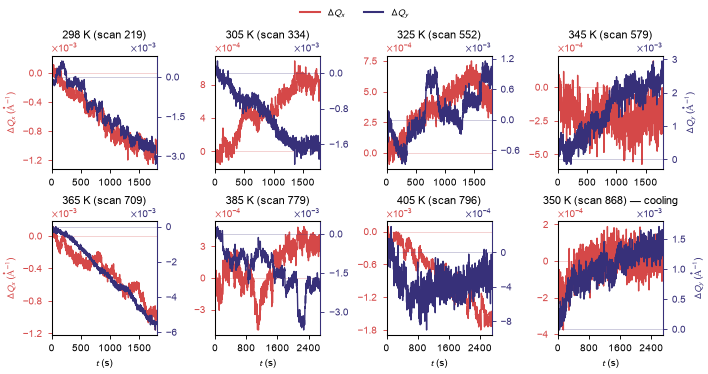

In [6]:
fig, axes = plt.subplots(
    2, 4,
    figsize=(180 * mm, 95 * mm),
    sharex=False,
    constrained_layout=True,
)

right_axes = []
for panel, (ax, scan) in enumerate(zip(axes.flat, SCANS)):
    if scan not in com:
        ax.set_visible(False)
        continue

    result = com[scan]
    t = result["time"]
    ax_r = ax.twinx()
    right_axes.append(ax_r)

    # ΔQ relative to the first valid frame of each scan
    good_x = np.flatnonzero(np.isfinite(result["Qx"]))
    good_y = np.flatnonzero(np.isfinite(result["Qy"]))
    qx0 = result["Qx"][good_x[0]] if good_x.size else np.nan
    qy0 = result["Qy"][good_y[0]] if good_y.size else np.nan
    delta_qx = result["Qx"] - qx0
    delta_qy = result["Qy"] - qy0

    ax.plot(t, delta_qx, color=QX_COLOR, lw=1.0)
    ax_r.plot(t, delta_qy, color=QY_COLOR, lw=1.0)
    ax.axhline(0, color=QX_COLOR, lw=0.5, alpha=0.35)
    ax_r.axhline(0, color=QY_COLOR, lw=0.5, alpha=0.35)

    T = float(config[f"{scan}_temperature"])
    cooling = " — cooling" if scan == "868" else ""
    ax.set_title(f"{T:.0f} K (scan {scan}){cooling}", pad=3)

    ax.tick_params(
        axis="y", which="both", colors=QX_COLOR,
        direction="out", length=3, width=0.65,
    )
    ax_r.tick_params(
        axis="y", which="both", colors=QY_COLOR,
        direction="out", length=3, width=0.65,
    )
    ax.tick_params(axis="x", which="both", direction="out", length=3, width=0.65)
    ax.spines["left"].set_color(QX_COLOR)
    ax_r.spines["right"].set_color(QY_COLOR)
    if panel % 4 == 0:
        ax.set_ylabel(r"$\Delta Q_x$ ($\mathrm{\AA}^{-1}$)", color=QX_COLOR)
    if panel % 4 == 3:
        ax_r.set_ylabel(r"$\Delta Q_y$ ($\mathrm{\AA}^{-1}$)", color=QY_COLOR)

    ax.yaxis.set_major_locator(MaxNLocator(4))
    ax_r.yaxis.set_major_locator(MaxNLocator(4))
    ax.xaxis.set_major_locator(MaxNLocator(4))
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useMathText=True)
    ax_r.ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useMathText=True)
    ax.yaxis.get_offset_text().set_color(QX_COLOR)
    ax_r.yaxis.get_offset_text().set_color(QY_COLOR)
    ax.margins(x=0)
    ax_r.margins(x=0)

for ax in axes[-1, :]:
    if ax.get_visible():
        ax.set_xlabel(r"$t$ (s)")

fig.legend(
    handles=[
        Line2D([0], [0], color=QX_COLOR, lw=1.5, label=r"$\Delta Q_x$"),
        Line2D([0], [0], color=QY_COLOR, lw=1.5, label=r"$\Delta Q_y$"),
    ],
    loc="outside upper center",
    ncols=2,
    frameon=False,
)

out = FIGURE_PATH / "q_center_of_mass_evolution.pdf"
fig.savefig(out, dpi=300, bbox_inches="tight", metadata={"Creator": ""})
print(f"wrote {out}")
plt.show()


Computing scan 219 ...
  x=510.51 px, y=699.72 px
Computing scan 334 ...
  x=502.11 px, y=684.84 px
Computing scan 552 ...
  x=500.79 px, y=683.27 px
Computing scan 579 ...
  x=507.85 px, y=694.21 px
Computing scan 709 ...
  x=496.13 px, y=700.50 px
Computing scan 779 ...
  x=508.36 px, y=699.22 px
Computing scan 796 ...
  x=505.81 px, y=691.38 px
Computing scan 868 ...
  x=515.05 px, y=711.25 px
wrote ../figures/q_center_of_mass_evolution_pixels.pdf


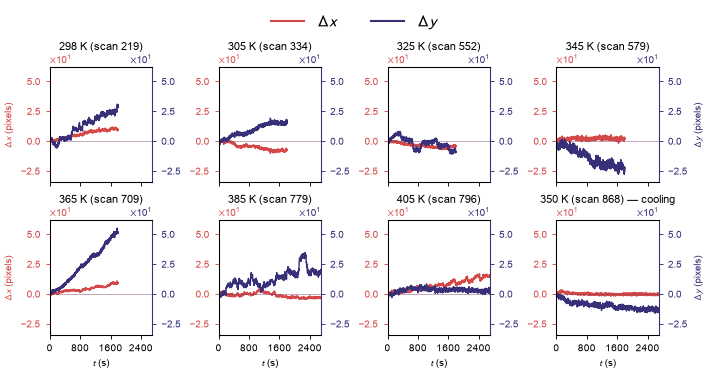

In [3]:
def intensity_pixel_com(path, dataset=DATASET, hot_pixel_threshold=HOT_PIXEL_THRESHOLD):
    """Framewise intensity-weighted center of mass in detector pixels.

    x is the column index and y is the row index. The hot-pixel cutoff and
    invalid-Q mask match intensity_q_com, so both centers use the same pixels.
    """
    with h5py.File(path, "r") as f:
        det = f[dataset]
        qx = np.asarray(f["pre_processing/Qx"][:], dtype=np.float64)
        qy = np.asarray(f["pre_processing/Qy"][:], dtype=np.float64)
        dt = float(f["experimental_parameters/frame_spacing"][0])

        valid_q = np.isfinite(qx) & np.isfinite(qy)
        rows = np.arange(det.shape[1], dtype=np.float64)
        cols = np.arange(det.shape[2], dtype=np.float64)

        nframes = det.shape[0]
        chunk_frames = det.chunks[0] if det.chunks else 16
        x_com = np.full(nframes, np.nan, dtype=float)
        y_com = np.full(nframes, np.nan, dtype=float)

        for start in range(0, nframes, chunk_frames):
            stop = min(start + chunk_frames, nframes)
            frames = np.asarray(det[start:stop])
            frames[frames > hot_pixel_threshold] = 0
            if not np.all(valid_q):
                frames[:, ~valid_q] = 0

            denom = frames.sum(axis=(1, 2), dtype=np.float64)
            x_num = np.einsum(
                "fij,j->f", frames, cols,
                dtype=np.float64, casting="unsafe", optimize=True,
            )
            y_num = np.einsum(
                "fij,i->f", frames, rows,
                dtype=np.float64, casting="unsafe", optimize=True,
            )

            good = denom > 0
            sl = slice(start, stop)
            x_com[sl][good] = x_num[good] / denom[good]
            y_com[sl][good] = y_num[good] / denom[good]

        time = np.arange(nframes, dtype=float) * dt

    return {"time": time, "x": x_com, "y": y_com, "dt": dt}


pix = {}
for scan in SCANS:
    path = processed_path(scan)
    if not path.exists():
        print(f"Skipping missing scan {scan}")
        continue
    print(f"Computing scan {scan} ...")
    pix[scan] = intensity_pixel_com(path)
    print(
        f"  x={np.nanmean(pix[scan]['x']):.2f} px, "
        f"y={np.nanmean(pix[scan]['y']):.2f} px"
    )

fig, axes = plt.subplots(
    2, 4,
    figsize=(180 * mm, 95 * mm),
    sharex=True,
    constrained_layout=True,
)

plotted = []
for panel, (ax, scan) in enumerate(zip(axes.flat, SCANS)):
    if scan not in pix:
        ax.set_visible(False)
        continue

    result = pix[scan]
    t = result["time"]
    ax_r = ax.twinx()
    plotted.append((ax, ax_r))

    good_x = np.flatnonzero(np.isfinite(result["x"]))
    good_y = np.flatnonzero(np.isfinite(result["y"]))
    x0 = result["x"][good_x[0]] if good_x.size else np.nan
    y0 = result["y"][good_y[0]] if good_y.size else np.nan
    delta_x = result["x"] - x0
    delta_y = result["y"] - y0

    ax.plot(t, delta_x, color=QX_COLOR, lw=1.0)
    ax_r.plot(t, delta_y, color=QY_COLOR, lw=1.0)
    ax.axhline(0, color=QX_COLOR, lw=0.5, alpha=0.35)
    ax_r.axhline(0, color=QY_COLOR, lw=0.5, alpha=0.35)

    T = float(config[f"{scan}_temperature"])
    cooling = " — cooling" if scan == "868" else ""
    ax.set_title(f"{T:.0f} K (scan {scan}){cooling}", pad=3)

    ax.tick_params(
        axis="y", which="both", colors=QX_COLOR,
        direction="out", length=3, width=0.65,
    )
    ax_r.tick_params(
        axis="y", which="both", colors=QY_COLOR,
        direction="out", length=3, width=0.65,
    )
    ax.tick_params(axis="x", which="both", direction="out", length=3, width=0.65)
    ax.spines["left"].set_color(QX_COLOR)
    ax_r.spines["right"].set_color(QY_COLOR)
    if panel % 4 == 0:
        ax.set_ylabel(r"$\Delta x$ (pixels)", color=QX_COLOR)
    if panel % 4 == 3:
        ax_r.set_ylabel(r"$\Delta y$ (pixels)", color=QY_COLOR)

    ax.yaxis.set_major_locator(MaxNLocator(4))
    ax_r.yaxis.set_major_locator(MaxNLocator(4))
    ax.xaxis.set_major_locator(MaxNLocator(4))
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useMathText=True)
    ax_r.ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useMathText=True)
    ax.yaxis.get_offset_text().set_color(QX_COLOR)
    ax_r.yaxis.get_offset_text().set_color(QY_COLOR)
    ax.margins(x=0)
    ax_r.margins(x=0)

def _padded_ylim(series, pad=0.08):
    vals = np.concatenate([np.asarray(a, float).ravel() for a in series])
    vals = vals[np.isfinite(vals)]
    lo, hi = float(np.min(vals)), float(np.max(vals))
    span = hi - lo
    if span == 0:
        span = max(abs(lo), 1.0)
    return lo - pad * span, hi + pad * span

dx_all, dy_all = [], []
for scan in SCANS:
    if scan not in pix:
        continue
    result = pix[scan]
    good_x = np.flatnonzero(np.isfinite(result["x"]))
    good_y = np.flatnonzero(np.isfinite(result["y"]))
    if good_x.size:
        dx_all.append(result["x"] - result["x"][good_x[0]])
    if good_y.size:
        dy_all.append(result["y"] - result["y"][good_y[0]])

ymin, ymax = _padded_ylim(dx_all + dy_all)
t_lo = min(float(np.nanmin(pix[s]["time"])) for s in SCANS if s in pix)
t_hi = max(float(np.nanmax(pix[s]["time"])) for s in SCANS if s in pix)
for ax, ax_r in plotted:
    ax.set_xlim(t_lo, t_hi)
    ax.set_ylim(ymin, ymax)
    ax_r.set_ylim(ymin, ymax)

for ax in axes[-1, :]:
    if ax.get_visible():
        ax.set_xlabel(r"$t$ (s)")

fig.legend(
    handles=[
        Line2D([0], [0], color=QX_COLOR, lw=1.5, label=r"$\Delta x$"),
        Line2D([0], [0], color=QY_COLOR, lw=1.5, label=r"$\Delta y$"),
    ],
    loc="outside upper center",
    ncols=2,
    fontsize=12,
    frameon=False,
)

out = FIGURE_PATH / "q_center_of_mass_evolution_pixels.pdf"
fig.savefig(out, dpi=300, bbox_inches="tight", metadata={"Creator": ""})
print(f"wrote {out}")
plt.show()
